# 138 · Why world models need a stochastic state: a pole released upright falls left or right

In [1]:
import numpy as np, mujoco, torch, torch.nn as nn, matplotlib.pyplot as plt

XML = """<mujoco><option timestep="0.005"/>
<worldbody><light pos="0 -1 3"/>
  <geom type="plane" size="2 1 .1" rgba=".9 .9 .9 1"/>
  <body name="pole" pos="0 0 .05">
    <joint name="hinge" type="hinge" axis="0 1 0" limited="true" range="-75 75" damping=".01"/>
    <geom type="capsule" fromto="0 0 0 0 0 .5" size=".01" mass=".01" rgba=".5 .5 .8 1"/>
    <body name="ball" pos="0 0 .5"><geom type="sphere" size=".04" mass=".1" rgba=".9 .3 .2 1"/></body>
  </body>
</worldbody></mujoco>"""
T = 100                                  # 2 s at 50 Hz: every release has fallen to one side by then

def drop(rng):
    """Release the pole almost upright: a nudge far below what any sensor would resolve decides left or right."""
    m = mujoco.MjModel.from_xml_string(XML); d = mujoco.MjData(m)
    d.qpos[0] = rng.normal(0, 0.003); d.qvel[0] = rng.normal(0, 0.05)
    mujoco.mj_forward(m, d)
    ball = lambda: d.body("ball").xpos[[0, 2]].copy()
    # what a real sensor reports: angle to 0.05 rad, angular velocity to 0.2 rad/s -> the nudge is invisible,
    # so every release LOOKS identical and only a stochastic model can say 'left OR right'
    obs0 = np.r_[np.round(ball(), 2), np.round(d.qpos[0] / 0.05) * 0.05, np.round(d.qvel[0] / 0.2) * 0.2]
    traj = []
    for t in range(T):
        mujoco.mj_step(m, d, 4); traj.append(ball())
    return obs0.astype(np.float32), np.array(traj, np.float32)

class Deterministic(nn.Module):
    def __init__(self):
        super().__init__(); self.net = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2 * T))
    def forward(self, o, z=None):
        return self.net(o).view(-1, T, 2)

class Stochastic(nn.Module):
    """Conditional VAE over the future: z captures what the observation cannot determine (which side)."""
    def __init__(self, zd=2):
        super().__init__(); self.zd = zd
        self.enc = nn.Sequential(nn.Linear(4 + 2 * T, 128), nn.ReLU(), nn.Linear(128, 2 * zd))
        self.dec = nn.Sequential(nn.Linear(4 + zd, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2 * T))
    def forward(self, o, z):
        return self.dec(torch.cat([o, z], -1)).view(-1, T, 2)

In [2]:
rng = np.random.default_rng(0)
data = [drop(rng) for _ in range(800)]
O = torch.tensor(np.stack([d[0] for d in data])); Y = torch.tensor(np.stack([d[1] for d in data]))
print("final x of the ball: fraction landing right =", float((Y[:, -1, 0] > 0).float().mean()))
det, sto = Deterministic(), Stochastic()
for net in [det, sto]:
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    for step in range(3000):
        idx = torch.randint(0, len(O), (128,)); o, y = O[idx] * 100, Y[idx]
        if net is det:
            loss = ((det(o) - y) ** 2).mean()
        else:
            mu, lv = sto.enc(torch.cat([o, y.flatten(1)], -1)).chunk(2, -1); z = mu + (0.5 * lv).exp() * torch.randn_like(mu)
            loss = ((sto(o, z) - y) ** 2).mean() + 1e-3 * (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(-1)).mean()
        opt.zero_grad(); loss.backward(); opt.step()

final x of the ball: fraction landing right = 0.48625001311302185


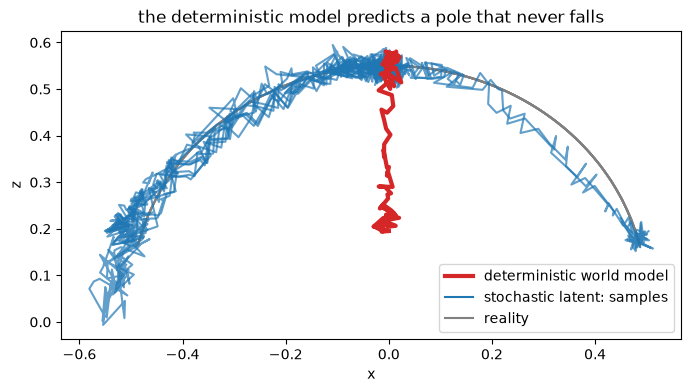

deterministic final x = 0.000 (reality never ends near 0) | stochastic samples final x = [-0.5, 0.5, -0.51, -0.5, -0.51, -0.52, -0.5, 0.5, -0.51, -0.46, -0.5, -0.5]


In [3]:
o = O[:1] * 100
with torch.no_grad():
    yd = det(o)[0]; ys = [sto(o, torch.randn(1, 2))[0] for _ in range(12)]
plt.figure(figsize=(8, 4))
for d in data[:30]:
    plt.plot(d[1][:, 0], d[1][:, 1], c="gray", alpha=0.3)
for y in ys:
    plt.plot(y[:, 0], y[:, 1], c="tab:blue", alpha=0.7)
plt.plot(yd[:, 0], yd[:, 1], c="tab:red", lw=3, label="deterministic world model")
plt.plot([], [], c="tab:blue", label="stochastic latent: samples"); plt.plot([], [], c="gray", label="reality")
plt.xlabel("x"); plt.ylabel("z"); plt.legend(); plt.title("the deterministic model predicts a pole that never falls"); plt.show()
print(f"deterministic final x = {yd[-1, 0]:.3f} (reality never ends near 0) | stochastic samples final x = {[round(float(y[-1, 0]), 2) for y in ys]}")